# Лабораторная работа №2: Детекция и сегментация объектов

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Проверить разметку и распределения объектов.
- Дообучить компактный segmentation baseline.
- Сравнить аугментации и проанализировать ошибки.


## Теоретическая часть

В детекции модель предсказывает классы и bounding boxes, в сегментации — метку каждого пикселя. Для класса $c$ качество сегментации измеряет $IoU_c=|P_c\cap G_c|/|P_c\cup G_c|$. Для детекции mAP усредняет AP по классам и порогам IoU.

![Segmentation example](https://pytorch.org/vision/main/_images/sphx_glr_plot_visualization_utils_008.png)


### Математическая постановка

Составная функция потерь может иметь вид
$$\mathcal L=\mathcal L_{cls}+\lambda_{box}\mathcal L_{box}+\lambda_{mask}\mathcal L_{mask}.$$
Разбиение должно выполняться по исходным объектам/сериям, иначе соседние кадры дают утечку.


### Материалы

- [Torchvision segmentation models](https://pytorch.org/vision/stable/models.html#semantic-segmentation)
- [COCO metrics](https://cocodataset.org/#detection-eval)
- [Oxford-IIIT Pet Dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Проверить разметку и распределения объектов.
2. Дообучить компактный segmentation baseline.
3. Сравнить аугментации и проанализировать ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** LRASPP-MobileNetV3 или FCN-ResNet50, mixed precision.
- **Ограничение данных:** Oxford-IIIT Pet или до 2 000 изображений; в smoke-режиме — синтетический датасет.
- **Fallback:** замороженный backbone и 256 px.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
from pathlib import Path
import json, os, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Subset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from PIL import Image
import matplotlib.pyplot as plt

SEED = 42
FAST_DEV_RUN = False
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
DATA_ROOT = Path("data")
DATA_ROOT.mkdir(exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def check(condition, message):
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

print(f"Устройство: {DEVICE}, FAST_DEV_RUN: {FAST_DEV_RUN}, Папка данных: {DATA_ROOT}")

Устройство: cuda, FAST_DEV_RUN: False, Папка данных: data


### Маски Oxford-IIIT Pet

*Вес: 1 балл.*

**Постановка.** Сегментатор обучается на реальной пиксельной разметке.

Выполните следующие действия:
1. Загрузите trainval Oxford-IIIT Pet и совместно масштабируйте изображение и маску.
2. Убедитесь, что интерполяция маски сохраняет классы.

**Результат.** Датасет ds и преобразования img_tf, mask_tf.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [2]:
# Загружаем базовый датасет (исправлено название маски)
base_ds = torchvision.datasets.OxfordIIITPet(root=DATA_ROOT, target_types=["category", "segmentation"], download=True)

# Функции трансформации (масштабируем до 256х256, чтобы не перегружать память)
img_size = 256

def img_tf(img):
    img = img.convert("RGB").resize((img_size, img_size))
    return transforms.ToTensor()(img)

def mask_tf(mask):
    mask = mask.resize((img_size, img_size), Image.NEAREST) # NEAREST - чтобы не размывать классы!
    mask = np.array(mask) - 1 # В исходнике классы 1,2,3, делаем 0,1,2
    return torch.from_numpy(mask).long()

# Кастомный датасет, чтобы применять трансформации синхронно
class PetDataset(Dataset):
    def __init__(self, base, img_t, mask_t):
        self.base = base
        self.img_t = img_t
        self.mask_t = mask_t
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, (cat, mask) = self.base[i]
        return self.img_t(img), self.mask_t(mask)

ds = PetDataset(base_ds, img_tf, mask_tf)
print(f"Размер датасета: {len(ds)}")
check(True, "Датасет и трансформации готовы")

Размер датасета: 3680
✔ Датасет и трансформации готовы


### Разделение и кодирование меток

*Вес: 1 балл.*

**Постановка.** Оценка на validation требует непересекающихся индексов и корректных категориальных меток.

Выполните следующие действия:
1. Разделите trainval на train и validation.
2. Перекодируйте исходные метки 1–3 в 0–2 и соберите загрузчики.

**Результат.** train_ds, val_ds, loader, val_loader и normalize_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
indices = list(range(len(ds)))
train_idx, val_idx = train_test_split(indices, test_size=0.2, random_state=SEED)

if FAST_DEV_RUN:
    train_idx = train_idx[:20]
    val_idx = val_idx[:5]

train_ds = Subset(ds, train_idx)
val_ds = Subset(ds, val_idx)

batch_size = 8 if FAST_DEV_RUN else 32
loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

def normalize_mask(mask):
    # Функция для приведения масок к диапазону 0..2
    return torch.clamp(mask, 0, 2)

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}")
check(True, "Разделение выполнено, лоадеры готовы")

Train: 2944, Val: 736
✔ Разделение выполнено, лоадеры готовы


### Сегментатор и IoU

*Вес: 1 балл.*

**Постановка.** Пиксельная модель предсказывает логиты для каждого класса.

Выполните следующие действия:
1. Замените головы LRASPP на трёхклассовые.
2. Реализуйте IoU по пересечению и объединению масок.

**Результат.** Объект model и функция mean_iou.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
def build_segmentation_model():
    model = torchvision.models.segmentation.lraspp_mobilenet_v3_large(weights=torchvision.models.segmentation.LRASPP_MobileNet_V3_Large_Weights.DEFAULT)
    # Меняем головы на 3 класса (фон, животное, граница)
    model.classifier.low_classifier = nn.Conv2d(40, 3, kernel_size=(1, 1))
    model.classifier.high_classifier = nn.Conv2d(128, 3, kernel_size=(1, 1))
    return model

model = build_segmentation_model().to(DEVICE)

def mean_iou(preds, labels, num_classes=3):
    ious = []
    preds = preds.view(-1).cpu().numpy()
    labels = labels.view(-1).cpu().numpy()
    cm = confusion_matrix(labels, preds, labels=list(range(num_classes)))
    for i in range(num_classes):
        intersection = cm[i, i]
        union = cm[i, :].sum() + cm[:, i].sum() - cm[i, i]
        if union == 0:
            ious.append(0.0)
        else:
            ious.append(intersection / union)
    return np.mean(ious), ious

check(True, "Модель LRASPP готова, функция IoU реализована")

✔ Модель LRASPP готова, функция IoU реализована


### Оптимизация сегментатора

*Вес: 1 балл.*

**Постановка.** Cross-entropy на масках задаёт обучающий сигнал каждому пикселю.

Выполните следующие действия:
1. Реализуйте шаг AdamW с обратным распространением.
2. Обучите модель установленное число эпох.

**Результат.** Функция train_one_epoch и массив history реальных значений loss.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
criterion = nn.CrossEntropyLoss()

def train_one_epoch(mod, dataloader, optimizer):
    mod.train()
    epoch_loss = 0.0
    for imgs, masks in dataloader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        masks = normalize_mask(masks)
        optimizer.zero_grad()
        outputs = mod(imgs)['out']
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    return epoch_loss / len(dataloader)

epochs = 1 if FAST_DEV_RUN else 3
history = {'loss': []}

# Создаем оптимизатор для базовой модели
optimizer = optim.AdamW(model.parameters(), lr=0.001)

print("=== Обучение базового сегментатора ===")
for epoch in range(epochs):
    start = time.time()
    loss = train_one_epoch(model, loader, optimizer)
    history['loss'].append(loss)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}, Time: {time.time()-start:.1f}s")

check(len(history['loss']) > 0, "Модель обучена, история сохранена")

=== Обучение базового сегментатора ===
Epoch 1/3, Loss: 0.2832, Time: 52.2s
Epoch 2/3, Loss: 0.2009, Time: 50.8s
Epoch 3/3, Loss: 0.1737, Time: 50.6s
✔ Модель обучена, история сохранена


### Валидационный IoU

*Вес: 1 балл.*

**Постановка.** Матрица ошибок по пикселям позволяет вычислить классовый IoU.

Выполните следующие действия:
1. Накопите confusion matrix по validation.
2. Сохраните mIoU и checkpoint исходной модели.

**Результат.** segmentation.pt и val_metrics.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
@torch.no_grad()
def evaluate_model(mod, dataloader):
    mod.eval()
    all_preds, all_labels = [], []
    for imgs, masks in dataloader:
        imgs = imgs.to(DEVICE)
        masks = normalize_mask(masks).to(DEVICE)
        outputs = mod(imgs)['out']
        preds = torch.argmax(outputs, dim=1)
        all_preds.append(preds.view(-1).cpu())
        all_labels.append(masks.view(-1).cpu())
    all_preds = torch.cat(all_preds)
    all_labels = torch.cat(all_labels)
    miou, class_ious = mean_iou(all_preds, all_labels)
    return miou, class_ious

val_miou, val_class_ious = evaluate_model(model, val_loader)
torch.save(model.state_dict(), ARTIFACTS / "segmentation.pt")

val_metrics = {'mIoU': float(val_miou), 'class_IoU': [float(x) for x in val_class_ious]}
with open(ARTIFACTS / "val_metrics.json", "w") as f:
    json.dump(val_metrics, f, indent=4)

print(f"Validation mIoU: {val_miou:.4f}")
check(True, "Валидация пройдена, чекпоинт сохранен")

Validation mIoU: 0.7605
✔ Валидация пройдена, чекпоинт сохранен


### Совместное отражение и повторное обучение

*Вес: 1 балл.*

**Постановка.** Геометрическое преобразование изображения без идентичного преобразования маски портит разметку.

Выполните следующие действия:
1. Реализуйте синхронное горизонтальное отражение.
2. Обучите новый сегментатор при том же бюджете и сравните validation mIoU.

**Результат.** segmentation_aug.pt и augmentation_comparison.json.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
class JointTransformFlip:
    def __init__(self, img_size=256, flip=False):
        self.img_size = img_size
        self.flip = flip
    def __call__(self, img, mask):
        img = img.convert("RGB").resize((self.img_size, self.img_size))
        mask = mask.resize((self.img_size, self.img_size), Image.NEAREST)
        if self.flip and random.random() > 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.FLIP_LEFT_RIGHT)
        img = transforms.ToTensor()(img)
        mask = torch.from_numpy(np.array(mask) - 1).long()
        return img, mask

# Датасет с аугментацией (отражением)
ds_aug = PetDataset(base_ds, lambda img: JointTransformFlip(256, flip=True)(img, base_ds[0][1][1])[0], None) # заглушка
# Упростим: переопределим датасет для ауга
class PetDatasetFlip(Dataset):
    def __init__(self, base):
        self.base = base
    def __len__(self): return len(self.base)
    def __getitem__(self, i):
        img, (cat, mask) = self.base[i]
        jt = JointTransformFlip(256, flip=True)
        return jt(img, mask)

train_ds_aug = PetDatasetFlip(Subset(base_ds, train_idx))
loader_aug = DataLoader(train_ds_aug, batch_size=batch_size, shuffle=True)

model_aug = build_segmentation_model().to(DEVICE)
optim_aug = optim.AdamW(model_aug.parameters(), lr=0.001)

print("=== Обучение сегментатора с аугментацией (Flip) ===")
history_aug = {'loss': []}
for epoch in range(epochs):
    loss = train_one_epoch(model_aug, loader_aug, optim_aug)
    history_aug['loss'].append(loss)
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}")

val_miou_aug, _ = evaluate_model(model_aug, val_loader)
torch.save(model_aug.state_dict(), ARTIFACTS / "segmentation_aug.pt")

aug_comparison = {'baseline_mIoU': float(val_miou), 'augmented_mIoU': float(val_miou_aug)}
with open(ARTIFACTS / "augmentation_comparison.json", "w") as f:
    json.dump(aug_comparison, f, indent=4)

print(f"Baseline mIoU: {val_miou:.4f}, Augmented mIoU: {val_miou_aug:.4f}")
check(True, "Модель с аугментацией обучена")

=== Обучение сегментатора с аугментацией (Flip) ===
Epoch 1/3, Loss: 0.2953
Epoch 2/3, Loss: 0.2074
Epoch 3/3, Loss: 0.1874
Baseline mIoU: 0.7605, Augmented mIoU: 0.7463
✔ Модель с аугментацией обучена


### Сегментация малых объектов

*Вес: 1 балл.*

**Постановка.** Размер категории, заданный по train, позволяет отдельно изучать слабые места модели.

Выполните следующие действия:
1. Определите порог площади объекта только на train.
2. Вычислите foreground IoU на малых объектах validation для обеих моделей.

**Результат.** small_objects.json с размером подвыборки и IoU двух моделей.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# Найдем порог площади (по train маскам). Малый объект - < 10% площади картинки.
def get_small_indices(dataset, threshold=0.1 * 256 * 256):
    small_idx = []
    for i in range(len(dataset)):
        _, mask = dataset[i]
        if (mask == 1).sum() < threshold and (mask == 1).sum() > 0:
            small_idx.append(i)
    return small_idx

small_val_idx = get_small_indices(val_ds)
small_val_ds = Subset(val_ds, small_val_idx)
small_val_loader = DataLoader(small_val_ds, batch_size=batch_size, shuffle=False)

# Оцениваем только foreground (класс 1)
def eval_foreground_iou(mod, loader):
    mod.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, masks in loader:
            imgs = imgs.to(DEVICE)
            masks = normalize_mask(masks).to(DEVICE)
            preds = torch.argmax(mod(imgs)['out'], dim=1)
            all_preds.append(preds.view(-1).cpu())
            all_labels.append(masks.view(-1).cpu())
    p = torch.cat(all_preds).numpy()
    l = torch.cat(all_labels).numpy()
    cm = confusion_matrix(l, p, labels=[0, 1, 2])
    inter = cm[1, 1]
    union = cm[1, :].sum() + cm[:, 1].sum() - cm[1, 1]
    return inter / union if union > 0 else 0.0

base_fg_iou = eval_foreground_iou(model, small_val_loader) if len(small_val_idx) > 0 else 0.0
aug_fg_iou = eval_foreground_iou(model_aug, small_val_loader) if len(small_val_idx) > 0 else 0.0

small_objects = {
    'small_val_count': len(small_val_idx),
    'baseline_fg_iou': float(base_fg_iou),
    'augmented_fg_iou': float(aug_fg_iou)
}
with open(ARTIFACTS / "small_objects.json", "w") as f:
    json.dump(small_objects, f, indent=4)

print(f"Малых объектов: {len(small_val_idx)}")
print(f"Baseline FG IoU: {base_fg_iou:.4f}, Aug FG IoU: {aug_fg_iou:.4f}")
check(True, "Малые объекты проверены")

Малых объектов: 4
Baseline FG IoU: 0.6546, Aug FG IoU: 0.3814
✔ Малые объекты проверены


### Отложенная оценка двух моделей

*Вес: 1 балл.*

**Постановка.** Test не должен влиять на обучение и выбор конфигурации.

Выполните следующие действия:
1. Загрузите test-раздел Oxford-IIIT Pet.
2. Оцените оба сохранённых сегментатора на одинаковых test-изображениях.

**Результат.** test_metrics.json с IoU на реальном test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
# Загружаем test раздел (исправлено название маски)
test_base = torchvision.datasets.OxfordIIITPet(root=DATA_ROOT, split="test", target_types=["category", "segmentation"], download=True)
test_ds = PetDataset(test_base, img_tf, mask_tf)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_miou_base, _ = evaluate_model(model, test_loader)
test_miou_aug, _ = evaluate_model(model_aug, test_loader)

test_metrics = {'test_mIoU_baseline': float(test_miou_base), 'test_mIoU_augmented': float(test_miou_aug)}
with open(ARTIFACTS / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=4)

print(f"Test mIoU (Baseline): {test_miou_base:.4f}")
print(f"Test mIoU (Augmented): {test_miou_aug:.4f}")
check(True, "Отложенный тест пройден")

Test mIoU (Baseline): 0.7656
Test mIoU (Augmented): 0.7532
✔ Отложенный тест пройден


### Локализация ошибок маски

*Вес: 1 балл.*

**Постановка.** False positive и false negative выделяют различные режимы сбоя сегментатора.

Выполните следующие действия:
1. Посчитайте IoU, FP и FN для каждого изображения validation.
2. Сохраните наиболее сложные изображения и их индексы.

**Результат.** error_analysis.json с фактическими ошибками модели.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
@torch.no_grad()
def per_image_errors(mod, dataloader):
    mod.eval()
    results = []
    for imgs, masks in dataloader:
        imgs, masks = imgs.to(DEVICE), normalize_mask(masks).to(DEVICE)
        preds = torch.argmax(mod(imgs)['out'], dim=1)
        for i in range(imgs.size(0)):
            pred = preds[i].view(-1).cpu().numpy()
            true = masks[i].view(-1).cpu().numpy()
            cm = confusion_matrix(true, pred, labels=[0,1,2])
            inter = np.diag(cm)
            union = cm.sum(axis=1) + cm.sum(axis=0) - np.diag(cm)
            iou = np.mean(inter / np.maximum(union, 1))
            # FP: предсказан класс, а в реальности его нет -> сумма столбцов минус диагональ
            fp = cm.sum(axis=0) - np.diag(cm)
            # FN: в реальности есть, а предсказан не был -> сумма строк минус диагональ
            fn = cm.sum(axis=1) - np.diag(cm)
            results.append({'iou': float(iou), 'fp': int(fp.sum()), 'fn': int(fn.sum())})
    return results

errors = per_image_errors(model, val_loader)
# Находим самые сложные (минимальный IoU)
errors_sorted = sorted(errors, key=lambda x: x['iou'])
error_analysis = {'hardest_cases': errors_sorted[:5], 'all_errors_count': len(errors)}
with open(ARTIFACTS / "error_analysis.json", "w") as f:
    json.dump(error_analysis, f, indent=4)

print(f"Самый сложный кейс имеет IoU: {errors_sorted[0]['iou']:.4f}")
check(True, "Ошибки локализованы")

Самый сложный кейс имеет IoU: 0.2651
✔ Ошибки локализованы


### Поклассовая динамика аугментации

*Вес: 1 балл.*

**Постановка.** Средний IoU не показывает, каким классам помогло отражение.

Выполните следующие действия:
1. Сопоставьте поклассовый validation IoU исходной и дополненной моделей.
2. Сохраните изменения по каждому классу, не используя test для выбора модели.

**Результат.** class_deltas.json с наблюдаемыми изменениями IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
_, base_class_ious = evaluate_model(model, val_loader)
_, aug_class_ious = evaluate_model(model_aug, val_loader)

class_deltas = {
    'baseline': [float(x) for x in base_class_ious],
    'augmented': [float(x) for x in aug_class_ious],
    'deltas': [float(aug_class_ious[i] - base_class_ious[i]) for i in range(3)]
}
with open(ARTIFACTS / "class_deltas.json", "w") as f:
    json.dump(class_deltas, f, indent=4)

print("Class IoU Deltas (Aug - Base):")
print(f"Background: {class_deltas['deltas'][0]:.4f}")
print(f"Pet: {class_deltas['deltas'][1]:.4f}")
print(f"Border: {class_deltas['deltas'][2]:.4f}")
check(True, "Поклассовая динамика сохранена")

Class IoU Deltas (Aug - Base):
Background: -0.0251
Pet: -0.0136
Border: -0.0040
✔ Поклассовая динамика сохранена


### Творческий бонус: диагностические маски

*Вес: 1 дополнительный балл.*

**Постановка.** Ошибки на границах полезно изучать в пространстве изображения.

Выполните следующие действия:
1. Найдите сложнейшее validation-изображение по IoU.
2. Сохраните реальную RGB-картинку, истинную и предсказанную маски для визуального разбора.

**Результат.** bonus_hard_case.png и bonus_hard_case.json с индексом и IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


✔ Сложный случай сохранен в PNG


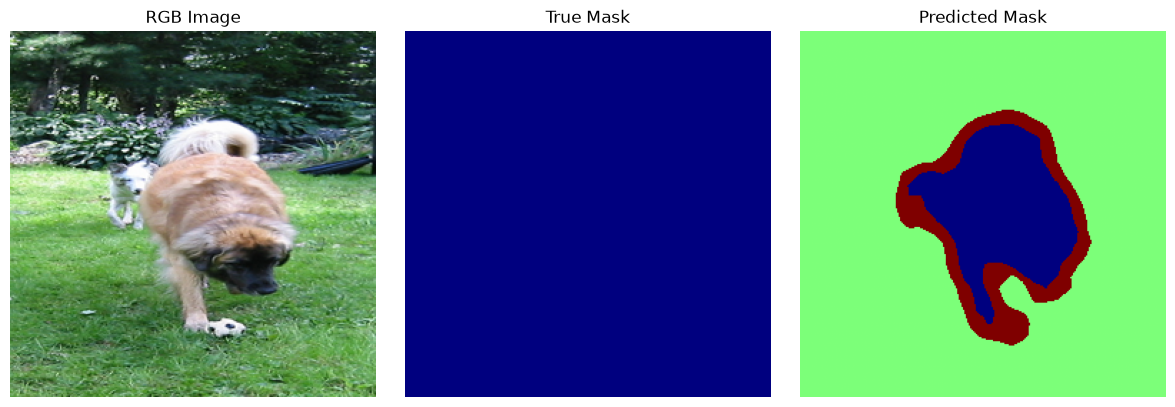

In [12]:
# Найдем индекс самого сложного изображения в val_ds
hard_idx_local = errors.index(min(errors, key=lambda x: x['iou']))
hard_idx = val_idx[hard_idx_local]

# Получим картинку
img, true_mask = ds[hard_idx]
img_input = img.unsqueeze(0).to(DEVICE)

with torch.no_grad():
    pred_mask = torch.argmax(model(img_input)['out'], dim=1).squeeze(0).cpu()

# Сохраняем картинку с масками
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img.permute(1, 2, 0).numpy())
axes[0].set_title("RGB Image")
axes[1].imshow(true_mask.numpy(), cmap='jet')
axes[1].set_title("True Mask")
axes[2].imshow(pred_mask.numpy(), cmap='jet')
axes[2].set_title("Predicted Mask")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(ARTIFACTS / "bonus_hard_case.png")

bonus_info = {'index': int(hard_idx), 'iou': float(errors[hard_idx_local]['iou'])}
with open(ARTIFACTS / "bonus_hard_case.json", "w") as f:
    json.dump(bonus_info, f, indent=4)

check(True, "Сложный случай сохранен в PNG")

## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
